In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print('Python:', sys.executable)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2}) 

Python: c:\Users\Legion\Downloads\ThucHanh\.venv\Scripts\python.exe
NumPy: 2.5.3 | pandas: 3.0.5


In [2]:
STUDY_DIR = Path(r'C:/Users/Legion/Downloads/ThucHanh/study')
DATA_DIR = STUDY_DIR / 'kuairec_data' / 'KuaiRec 2.0' / 'data'
SMALL_MATRIX_PATH = DATA_DIR / 'small_matrix.csv'
print('File:', SMALL_MATRIX_PATH)

File: C:\Users\Legion\Downloads\ThucHanh\study\kuairec_data\KuaiRec 2.0\data\small_matrix.csv


# 1. Đánh giá cấu trúc và chất lượng dữu liệu

In [3]:
df = pd.read_csv(SMALL_MATRIX_PATH)
df.info()
display(df.head())
display(df.tail())
display(df.sample(5, random_state=42))

<class 'pandas.DataFrame'>
RangeIndex: 4676570 entries, 0 to 4676569
Data columns (total 8 columns):
 #   Column          Dtype  
---  ------          -----  
 0   user_id         int64  
 1   video_id        int64  
 2   play_duration   int64  
 3   video_duration  int64  
 4   time            str    
 5   date            float64
 6   timestamp       float64
 7   watch_ratio     float64
dtypes: float64(3), int64(4), str(1)
memory usage: 384.1 MB


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
4676565,7162,2267,11908,5467,NaN,NaN,NaN,2.178160
4676566,7162,2065,11919,6067,NaN,NaN,NaN,1.964562
4676567,7162,1296,16690,19870,NaN,NaN,NaN,0.839960
4676568,7162,4822,11862,24400,NaN,NaN,NaN,0.486148
4676569,7162,4364,2182,19367,NaN,NaN,NaN,0.112666


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
224263,385,6088,3010,14240,2020-08-08 09:49:55.461,20200808.0,1.596851e+09,0.211376
2682796,4275,570,1543,25310,2020-07-29 20:38:30.483,20200729.0,1.596026e+09,0.060964
32875,55,7281,1276,6667,2020-08-28 07:44:46.355,20200828.0,1.598572e+09,0.191390
262283,477,7093,6709,28929,2020-07-14 19:24:31.309,20200714.0,1.594726e+09,0.231913
3228863,5000,7125,2976,6016,2020-07-18 11:21:36.833,20200718.0,1.595042e+09,0.494681


In [4]:
missing_summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_pct': df.isna().mean() * 100
})

display(missing_summary)

,dtype,missing_count,missing_pct
user_id,int64,0,0.00000
video_id,int64,0,0.00000
play_duration,int64,0,0.00000
video_duration,int64,0,0.00000
time,str,181992,3.89157
date,float64,181992,3.89157
timestamp,float64,181992,3.89157
watch_ratio,float64,0,0.00000


In [5]:
time_missing = df[['time', 'date', 'timestamp']].isna()
display(
    time_missing.value_counts()
    .rename('row_count')
    .reset_index()
)                    

,time,date,timestamp,row_count
0,False,False,False,4494578
1,True,True,True,181992


In [6]:
duplicate_summary = pd.Series({
    'Dòng trùng hoàn toàn': df.duplicated().sum(),
    'Cặp user-video lặp': df.duplicated(subset=['user_id', 'video_id']).sum(),
    'Số user': df['user_id'].nunique(),
    'Số video': df['video_id'].nunique()
})

display(duplicate_summary)

Dòng trùng hoàn toàn       0
Cặp user-video lặp         0
Số user                 1411
Số video                3327
dtype: int64

In [7]:
invalid_summary = pd.Series({
    'play_duration âm': (df['play_duration'] < 0).sum(),
    'video_duration âm': (df['video_duration'] < 0).sum(),
    'video_duration bằng 0': (df['video_duration'] == 0).sum(),
    'watch_ratio âm': (df['watch_ratio'] < 0).sum(),
    'watch_ratio vô hạn': np.isinf(df['watch_ratio']).sum() 
})

display(invalid_summary)

play_duration âm         0
video_duration âm        0
video_duration bằng 0    0
watch_ratio âm           0
watch_ratio vô hạn       0
dtype: int64

In [8]:
calculated_ratio = df['play_duration'] / df['video_duration']
ratio_error = (df['watch_ratio'] - calculated_ratio).abs()

ratio_matches = np.isclose(
    df['watch_ratio'],
    calculated_ratio,
    rtol=1e-6,
    atol=1e-8
)

print('Số dòng khớp:', ratio_matches.sum())
print('Số dòng không khớp:', (~ratio_matches).sum())
print('Sai lệch tuyệt đối lớn nhất:', ratio_error.max())

Số dòng khớp: 4674957
Số dòng không khớp: 1613
Sai lệch tuyệt đối lớn nhất: 0.002921739089867259


In [9]:
parsed_time = pd.to_datetime(
    df['time'],
    format='%Y-%m-%d %H:%M:%S.%f',
    errors='coerce'
)

parsed_timestamp = pd.to_datetime(
    df['timestamp'],
    unit='s',
    utc=True,
    errors='coerce'
)

time_check = pd.Series({
    'Có time nhưng không đọc được':
        (df['time'].notna() & parsed_time.isna()).sum(),
    'Có timestamp nhưng không đọc được':
        (df['timestamp'].notna() & parsed_timestamp.isna()).sum(),
    'Time sớm nhất': parsed_time.min(),
    'Time muộn nhất': parsed_time.max(),
    'Timestamp sớm nhất (UTC)': parsed_timestamp.min(),
    'Timestamp muộn nhất (UTC)': parsed_timestamp.max()
})

display(time_check)

Có time nhưng không đọc được                                           0
Có timestamp nhưng không đọc được                                      0
Time sớm nhất                                 2020-07-04 02:23:26.060000
Time muộn nhất                                2020-09-05 23:57:23.683000
Timestamp sớm nhất (UTC)             2020-07-03 18:23:26.059999943+00:00
Timestamp muộn nhất (UTC)            2020-09-05 15:57:23.683000088+00:00
dtype: object

In [10]:
date_from_time = pd.to_numeric(
    parsed_time.dt.strftime('%Y%m%d'),
    errors='coerce'
)

date_comparable = parsed_time.notna() & df['date'].notna()
date_mismatch = (
    date_from_time.loc[date_comparable]
    != df.loc[date_comparable, 'date']
)

print('Số dòng đối chiếu date và time:', date_comparable.sum())
print('Số dòng date không khớp time:', date_mismatch.sum())

time_comparable = parsed_time.notna() & parsed_timestamp.notna()

offset_seconds = (
    parsed_time.loc[time_comparable]
    - parsed_timestamp.loc[time_comparable].dt.tz_localize(None)
).dt.total_seconds()

print('\nSố dòng đối chiếu time và timestamp:', time_comparable.sum())

display(
    offset_seconds.round(3)
    .value_counts()
    .head(10)
    .rename_axis('Chênh lệch time − UTC (giây)')
    .reset_index(name='Số dòng')
)

print('Chênh lệch nhỏ nhất (giây):', offset_seconds.min())
print('Chênh lệch lớn nhất (giây):', offset_seconds.max())

Số dòng đối chiếu date và time: 4494578
Số dòng date không khớp time: 1213

Số dòng đối chiếu time và timestamp: 4494578


,Chênh lệch time − UTC (giây),Số dòng
0,28800.0,4494578


Chênh lệch nhỏ nhất (giây): 28799.999999882
Chênh lệch lớn nhất (giây): 28800.000000118


In [11]:
date_parsed = pd.to_datetime(
    df['date'].astype('Int64').astype('string'),
    format='%Y%m%d',
    errors='coerce'
)

print(
    'Có date nhưng không đọc được:',
    (df['date'].notna() & date_parsed.isna()).sum()
)

date_diff = (
    date_parsed - parsed_time.dt.normalize()
).dt.days

print('\nChênh lệch date − ngày trong time:')
display(date_diff.value_counts().sort_index())

date_from_utc = pd.to_numeric(
    parsed_timestamp.dt.strftime('%Y%m%d'),
    errors='coerce'
)

mismatch_mask = (
    date_comparable
    & df['date'].ne(date_from_time)
)

print(
    '\nTrong các dòng lệch, số dòng date khớp ngày UTC:',
    df.loc[mismatch_mask, 'date']
    .eq(date_from_utc.loc[mismatch_mask])
    .sum()
)

display(
    df.loc[
        mismatch_mask,
        ['user_id', 'video_id', 'time', 'date', 'timestamp']
    ].head(10)
)

Có date nhưng không đọc được: 0

Chênh lệch date − ngày trong time:


-1.0          3
 0.0    4493365
 1.0       1102
 2.0         25
 3.0          6
 4.0         32
 5.0         45
Name: count, dtype: int64


Trong các dòng lệch, số dòng date khớp ngày UTC: 3


,user_id,video_id,time,date,timestamp
27361,51,672,2020-07-21 23:29:33.62,20200722.0,1.595345e+09
30849,55,5624,2020-07-24 23:59:55.52,20200725.0,1.595606e+09
34029,64,4046,2020-07-22 16:55:25.883,20200723.0,1.595408e+09
34493,64,7262,2020-07-29 14:22:13.209,20200730.0,1.596004e+09
34597,64,8680,2020-07-30 23:39:32.782,20200731.0,1.596124e+09
43510,97,8506,2020-07-14 19:13:52.758,20200715.0,1.594725e+09
45363,97,8707,2020-08-09 22:29:24.719,20200810.0,1.596983e+09
50840,102,4038,2020-07-28 09:26:06.131,20200729.0,1.595900e+09
50847,102,762,2020-07-28 09:36:58.113,20200729.0,1.595900e+09
50861,102,7186,2020-07-28 09:52:34.507,20200729.0,1.595901e+09


- Dữ liệu có 4.676.570 dòng, gồm 8 cột, có 1.411 user và 3.327 video.
- Hầu hết các trường có ý nghĩa để phân tích hành vi xem không bị thiếu. Với những cột <code>time</code>, <code>date</code>, <code>timestamp</code>, mỗi cột đều thiếu 181.992 giá trị, chiếm khoảng 3,89%. Quan sát kỹ hơn, cả 3 cột thiếu đồng thời trên cùng các dòng. Tức là không có giá trị để trực tiếp khôi phục chéo giá trị thiếu trên các dòng này. 
- Khi kiểm tra trùng lặp, thấy không có dòng hay các cặp user-video nào trùng hoàn toàn hay lặp lại. 
- Các cột <code>play_duration</code>, <code>video_duration</code>, <code>watch_ratio</code> không có giá trị âm, bằng 0 hoặc vô hạn, không cần xử lý thêm. 
- Với cột <code>watch_ratio</code>, hầu hết số dòng khớp với ngưỡng được đặt ra, có một nhóm nhỏ chiếm 0,0345% là không khớp. 
- Kiểm tra dữ liệu cột <code>time</code> và <code>timestamp</code>, thấy có tính nhất quán với múi giờ Trung Quốc. Dữ liệu quan sát được trải dài từ 4/7/2020 đến 5/9/2020. Có 4.493.365 dòng có <code>date</code> khớp ngày trong <code>time</code>. Còn lại có 1213 dòng lệch <code>date</code> khác ngày trong <code>time</code>. 

# 2. Độ bao phủ của ma trận user–video

\- Mục đích của phần này là kiểm tra độ đầy đủ của các tương tác giữa người dùng và video trong tập <code>small_matrix</code>. Mỗi một cặp được coi là đã ***quan sát*** khi có dòng tương tác tương ứng trong tập. Việc kiểm tra sẽ thực hiện qua 3 góc nhìn : 
- Mật độ toàn mma trận
- Số video đã quan sát theo từng user
- Số user đã quan sát theo từng video

In [12]:
n_users = df['user_id'].nunique()
n_videos = df['video_id'].nunique()

possible_pairs = n_users * n_videos

observed_pairs = (
    df[['user_id', 'video_id']]
    .drop_duplicates()
    .shape[0]
)

missing_pairs = possible_pairs - observed_pairs
density = observed_pairs / possible_pairs

print(f'Số cặp có thể có: {possible_pairs:,}')
print(f'Số cặp đã quan sát: {observed_pairs:,}')
print(f'Số cặp chưa quan sát: {missing_pairs:,}')
print(f'Mật độ: {density:.4%}')

Số cặp có thể có: 4,694,397
Số cặp đã quan sát: 4,676,570
Số cặp chưa quan sát: 17,827
Mật độ: 99.6202%


In [13]:
user_coverage = (
    df.groupby('user_id')['video_id']
    .nunique()
    .rename('observed_videos')
    .to_frame()
)

user_coverage['missing_videos'] = (
    n_videos - user_coverage['observed_videos']
)

user_coverage['coverage_pct'] = (
    user_coverage['observed_videos'] / n_videos * 100
)

display(user_coverage.describe())

print(
    'Số user có đủ mọi video:',
    user_coverage['missing_videos'].eq(0).sum()
)

print(
    'Tổng số cặp thiếu theo user:',
    user_coverage['missing_videos'].sum()
)

display(
    user_coverage.sort_values('missing_videos', ascending=False)
    .head(10)
)

,observed_videos,missing_videos,coverage_pct
count,1411.000000,1411.000000,1411.000000
mean,3314.365698,12.634302,99.620249
std,6.984852,6.984852,0.209944
min,3295.000000,0.000000,99.038173
25%,3309.000000,7.000000,99.458972
50%,3315.000000,12.000000,99.639315
75%,3320.000000,18.000000,99.789600
max,3327.000000,32.000000,100.000000


Số user có đủ mọi video: 8
Tổng số cặp thiếu theo user: 17827


,observed_videos,missing_videos,coverage_pct
user_id,,,
5742,3295,32,99.038173
1853,3295,32,99.038173
1226,3296,31,99.068230
3246,3296,31,99.068230
4427,3296,31,99.068230
37,3297,30,99.098287
1898,3297,30,99.098287
3821,3297,30,99.098287
6336,3297,30,99.098287


- Xét thấy mỗi người dùng xem khoảng 3295 -> 3327 video, ứng với 99,04 -> 100%. Trung bình (Mean) mỗi người dùng thiếu khoảng 12,63 video (do chỉ lấy tổng tất cả chia trung bình nên ra số không nguyên). Trung vị (median ) là 12 video. Có 8 user xem qua tất cả video có trong <code>small_matrix_</code>. Có 2 người dùng thiếu nhiều video nhất, mỗi người 32 video là người dùng 5742 và 1853, nhưng độ bao phủ vẫn tương đối lớn, vẫn còn ý nghĩa để cho làm 1 điểm dữ liệu được. 

-> Độ bao phủ của người dùng với việc xem video là rất lớn, mọi người dùng đều có phản hồi trên gần như toàn bộ tập video. Kể cả những người dùng có độ bao phủ thấp nhất thì cũng có lượng video xem rất nhiều.

In [14]:
video_coverage = (
    df.groupby('video_id')['user_id']
    .nunique()
    .rename('observed_users')
    .to_frame()
)

video_coverage['missing_users'] = (
    n_users - video_coverage['observed_users']
)

video_coverage['coverage_pct'] = (
    video_coverage['observed_users'] / n_users * 100
)

display(video_coverage.describe())

print(
    'Số video có đủ mọi user:',
    video_coverage['missing_users'].eq(0).sum()
)

display(
    video_coverage.nlargest(10, 'missing_users')
)

,observed_users,missing_users,coverage_pct
count,3327.000000,3327.000000,3327.000000
mean,1405.641719,5.358281,99.620249
std,15.739335,15.739335,1.115474
min,1315.000000,0.000000,93.196315
25%,1410.000000,0.000000,99.929128
50%,1411.000000,0.000000,100.000000
75%,1411.000000,1.000000,100.000000
max,1411.000000,96.000000,100.000000


Số video có đủ mọi user: 2062


,observed_users,missing_users,coverage_pct
video_id,,,
784,1315,96,93.196315
9984,1315,96,93.196315
5973,1318,93,93.408930
7083,1319,92,93.479802
6742,1320,91,93.550673
6753,1320,91,93.550673
5818,1322,89,93.692417
3132,1323,88,93.763288
4230,1324,87,93.834160


\- Xét thấy có 2.062/3.327 video (chiếm khoảng 61,98% của tổng video trong small_matrix). Median độ bao phủ là 100%, mean mỗi video thiếu khoảng 5,36 người dùng. Xét 2 video thiếu nhiều nhất là 784 và 9984 thì mỗi video thiếu 96 người dùng, có độ bao phủ là 93,20%

-> Độ bao phủ theo video dao động từ 93,2% -> 100%. Có 2.062 video được tương tác từ toàn bộ 1.411 người dùng có trong <code>small_matrix</code>. Trung vị số user thiếu là 0, tối đa là 96. Tức là dữ liệu gần như đầy đủ ở cả 2 phía, nhưng mức độ biến động, nếu gom theo :
- user : tỷ lệ bao phủ đồng đều hơn, dao động từ 99,04 -> 100%, độ lệch chuẩn khoảng 0,21
- video : tỷ lệ bao phủ dao động hơn, từ 93,20 -> 100%, độ lệch chuẩn 1,12%

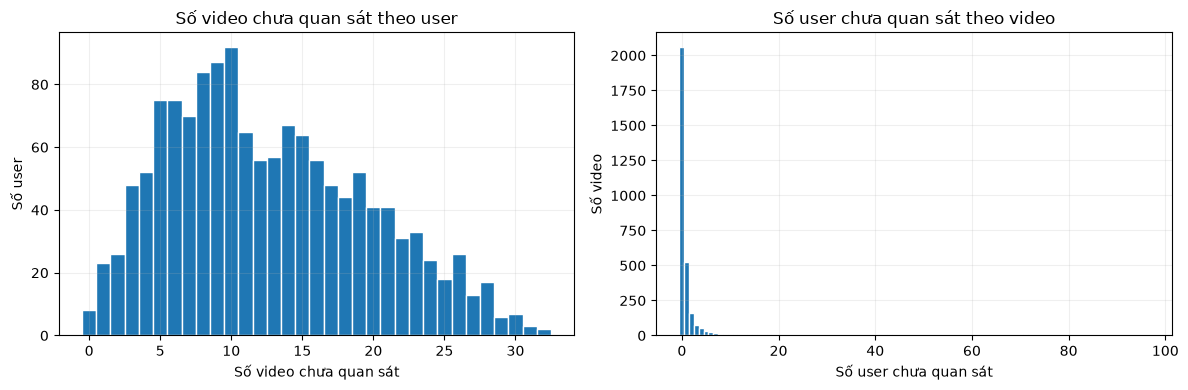

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    user_coverage['missing_videos'],
    bins=np.arange(
        -0.5,
        user_coverage['missing_videos'].max() + 1.5,
        1
    ),
    edgecolor='white'
)
axes[0].set_title('Số video chưa quan sát theo user')
axes[0].set_xlabel('Số video chưa quan sát')
axes[0].set_ylabel('Số user')

axes[1].hist(
    video_coverage['missing_users'],
    bins=np.arange(
        -0.5,
        video_coverage['missing_users'].max() + 1.5,
        1
    ),
    edgecolor='white'
)
axes[1].set_title('Số user chưa quan sát theo video')
axes[1].set_xlabel('Số user chưa quan sát')
axes[1].set_ylabel('Số video')

plt.tight_layout()
plt.show()

Số video chưa quan sát theo user phân bố quanh một vùng trung tâm, có dạng gần chuông nhưng hơi lệch phải. Ngược lại, số user chưa quan sát theo video lệch phải mạnh: 61,98% video có tương tác từ toàn bộ user, trong khi một nhóm nhỏ thiếu phản hồi từ nhiều user. Kết quả cho thấy phần thiếu phân bố đồng đều hơn theo user và tập trung hơn theo video. 

# 3. Mức độ xem video 

\- Mục đích là khám phá mức độ xem video, để xem trong các tương tác đã quan sát, người dùng thường xem một phần, xem hết hay xem lâu hơn? 

In [16]:
viewing_summary = df[
    ['play_duration', 'video_duration', 'watch_ratio']
].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

display(viewing_summary)

,play_duration,video_duration,watch_ratio
count,4.676570e+06,4.676570e+06,4.676570e+06
mean,8.612637e+03,1.448645e+04,9.070695e-01
std,1.223661e+04,2.046711e+04,1.362324e+00
min,0.000000e+00,3.067000e+03,0.000000e+00
25%,5.811000e+03,7.523000e+03,4.675769e-01
50%,7.549000e+03,9.600000e+03,7.691666e-01
75%,9.880000e+03,1.193400e+04,1.120590e+00
90%,1.271700e+04,2.183400e+04,1.558761e+00
95%,1.576100e+04,4.513400e+04,1.953971e+00
99%,3.149931e+04,1.398770e+05,3.585138e+00


- Median của <code>watch_ratio</code> khoảng 0,769 -> tức là một nửa tương tác có thời gian xem không quá 76,9% thời lượng video. 99% tương tác của <code>watch_ratio</code> không vượt quá 3,585; nhưng max lên tới 571,521 -> có thể là bot?. Min của <code>watch_ratio</code> và <code>play_duration</code> -> cho thấy tồn tại các bản ghi có thời gian xem bằng 0.

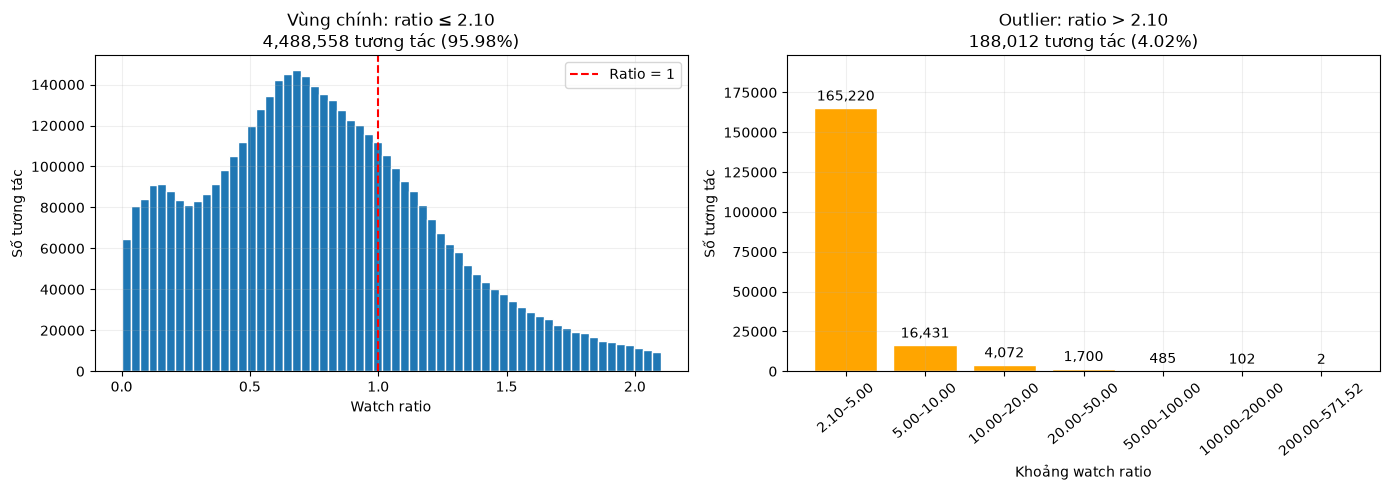

Ngưỡng outlier: 2.1001
Ratio lớn nhất: 571.5214
Tổng tương tác ở hai biểu đồ: 4,676,570


In [22]:
ratio = df['watch_ratio']

q1 = ratio.quantile(0.25)
q3 = ratio.quantile(0.75)
upper_bound = q3 + 1.5 * (q3 - q1)

main_ratio = ratio[ratio <= upper_bound]
outlier_ratio = ratio[ratio > upper_bound]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(main_ratio, bins=60, edgecolor='white')
axes[0].axvline(
    1, color='red', linestyle='--', label='Ratio = 1'
)
axes[0].set_title(
    f'Vùng chính: ratio ≤ {upper_bound:.2f}\n'
    f'{len(main_ratio):,} tương tác '
    f'({len(main_ratio) / len(ratio):.2%})'
)
axes[0].set_xlabel('Watch ratio')
axes[0].set_ylabel('Số tương tác')
axes[0].ticklabel_format(axis='y', style='plain')
axes[0].legend()

edges = [upper_bound, 5, 10, 20, 50, 100, 200, ratio.max()]
counts, _ = np.histogram(outlier_ratio, bins=edges)

labels = [
    f'{edges[i]:.2f}–{edges[i + 1]:.2f}'
    for i in range(len(edges) - 1)
]

bars = axes[1].bar(
    labels, counts, color='orange', edgecolor='white'
)
axes[1].bar_label(bars, labels=[f'{n:,}' for n in counts], padding=3)

axes[1].set_title(
    f'Outlier: ratio > {upper_bound:.2f}\n'
    f'{len(outlier_ratio):,} tương tác '
    f'({len(outlier_ratio) / len(ratio):.2%})'
)
axes[1].set_xlabel('Khoảng watch ratio')
axes[1].set_ylabel('Số tương tác')
axes[1].tick_params(axis='x', labelrotation=40)
axes[1].ticklabel_format(axis='y', style='plain')
axes[1].set_ylim(0, counts.max() * 1.2)

plt.tight_layout()
plt.show()

print(f'Ngưỡng outlier: {upper_bound:.4f}')
print(f'Ratio lớn nhất: {ratio.max():.4f}')
print(f'Tổng tương tác ở hai biểu đồ: {len(main_ratio) + counts.sum():,}')

Biểu đồ trái thể hiện phân phối trong vùng tương tác chính. Biểu đồ phải tổng hợp các tương tác vượt ngưỡng outlier, được định nghĩa ở đây là mốc đánh giấu vị trí nằm xa vùng tập trung dữ liệu, gồm giá trị cực lớn.